# 02 — EDA (eksploracyjna analiza danych)

**Cel notebooka:** zanim zbudujemy model, zrozumieć dane i sprawdzić, co naprawdę wpływa na wynik wyścigu. Wczytujemy wyłącznie pliki CSV z `01_dane` — bez API.

> ⚠️ **Nie uruchamiaj ponownie `01_dane` po zakończeniu wyścigu.** GP Meksyku jest dzisiaj, więc gdy się skończy, API zwróci jego wynik i trafiłby on do danych treningowych. Chcemy przewidywać Meksyk tak, jakby jeszcze się nie odbył, więc zostajemy przy zapisanych CSV.

## 2.1 Wczytanie danych

**Co robimy:** wczytujemy zapisane tabele i sprawdzamy ich rozmiary.

**Dlaczego:** każdy kolejny notebook zaczyna się od CSV, więc pierwsza kontrola to: czy wszystko się wczytało i czy rozmiary się zgadzają z tym, co widzieliśmy w `01_dane`.

In [8]:
import pandas as pd

races = pd.read_csv("data/races_2026.csv")
results = pd.read_csv("data/results_2026.csv")
quali = pd.read_csv("data/quali_2026.csv")
sprint = pd.read_csv("data/sprint_2026.csv")
fastest_laps = pd.read_csv("data/fastest_laps_2026.csv")
teammate_hist = pd.read_csv("data/teammate_gaps_hist.csv")
mexico_hist = pd.read_csv("data/mexico_hist.csv")

for name, df in [("races", races), ("results", results), ("quali", quali), ("sprint", sprint),
                 ("fastest_laps", fastest_laps), ("teammate_hist", teammate_hist), ("mexico_hist", mexico_hist)]:
    print(f"{name:15} {df.shape}")

races           (19, 17)
results         (396, 15)
quali           (413, 14)
sprint          (132, 15)
fastest_laps    (18, 7)
teammate_hist   (1370, 5)
mexico_hist     (60, 8)


## 2.2 Czy pole position wygrywa?

**Co robimy:** dla każdego z 18 zakończonych wyścigów zestawiamy, kto stał na pole position i kto wygrał, i liczymy, jak często to ta sama osoba.

**Dlaczego:** to nasz punkt odniesienia (*baseline*). Jeśli „zwycięzcą będzie ten, kto ma pole" trafia w większości wyścigów, to model musi być lepszy od tej prostej reguły, żeby miał sens.

In [9]:
done_rounds = results["round"].unique()

pole = quali[(quali["round"].isin(done_rounds)) & (quali["position"] == 1)][["round", "name_acronym"]].rename(columns={"name_acronym": "pole"})
win = results[results["position"] == 1][["round", "name_acronym"]].rename(columns={"name_acronym": "winner"})

pole_vs_win = pole.merge(win, on="round")
pole_vs_win["pole_won"] = pole_vs_win["pole"] == pole_vs_win["winner"]

print(f"Pole position wygrało {pole_vs_win['pole_won'].sum()} z {len(pole_vs_win)} wyścigów ({pole_vs_win['pole_won'].mean():.0%})")
pole_vs_win

Pole position wygrało 13 z 18 wyścigów (72%)


,round,pole,winner,pole_won
0,1,RUS,RUS,True
1,2,ANT,ANT,True
2,3,ANT,ANT,True
3,4,ANT,ANT,True
4,5,RUS,ANT,False
5,6,ANT,ANT,True
6,7,RUS,HAM,False
7,8,RUS,RUS,True
8,9,ANT,LEC,False
9,10,ANT,ANT,True


## 2.3 Ile miejsc kierowcy zyskują lub tracą w wyścigu?

**Co robimy:** dla każdego kierowcy liczymy średnią różnicę między pozycją w kwalifikacjach a pozycją na mecie. Wartość dodatnia = wyprzedza, ujemna = traci miejsca.

**Dlaczego:** sama pozycja startowa nie mówi, kto jest dobry w wyścigu. Jeśli niektórzy kierowcy (np. ANT) systematycznie zyskują miejsca, a inni (np. RUS) je tracą, to model powinien o tym wiedzieć. Liczymy tylko wyścigi, które kierowca **ukończył**, żeby awaria nie udawała słabego tempa.

In [10]:
d = results[["round", "name_acronym", "team_name", "position", "dnf"]].merge(
    quali[["round", "name_acronym", "position"]],
    on=["round", "name_acronym"], suffixes=("_race", "_quali"),
)
d["gained"] = d["position_quali"] - d["position_race"]

finishers = d[~d["dnf"]]
gain_by_driver = (
    finishers.groupby("name_acronym")
    .agg(team=("team_name", "last"), races=("gained", "count"), avg_gain=("gained", "mean"))
    .round(2)
    .sort_values("avg_gain", ascending=False)
)
gain_by_driver

,team,races,avg_gain
name_acronym,,,
PER,Cadillac,13,4.00
STR,Aston Martin,6,3.50
ALO,Aston Martin,12,3.42
TSU,Racing Bulls,3,3.00
BOT,Cadillac,9,2.44
OCO,Haas F1 Team,17,2.18
HUL,Audi,14,2.07
LAW,Racing Bulls,17,1.94
ALB,Williams,10,1.80


### Wykres do 2.3

**Co robimy:** to samo co w tabeli, tylko jako wykres słupkowy. ANT i RUS mają podpisane wartości.

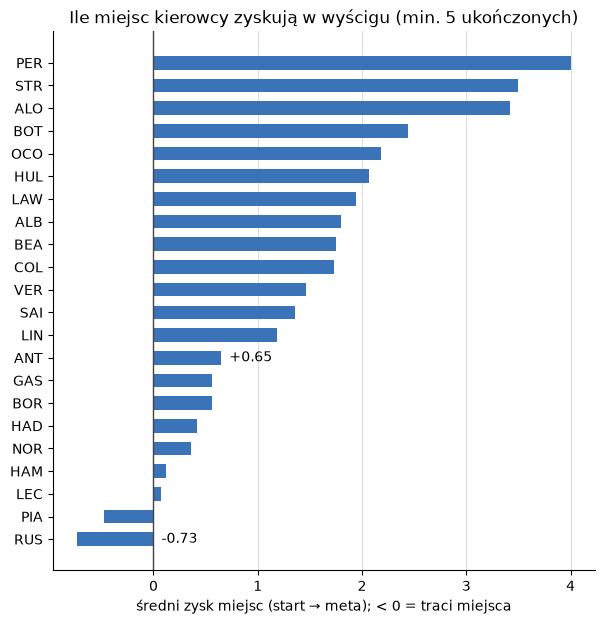

In [11]:
import matplotlib.pyplot as plt

plot_data = gain_by_driver[gain_by_driver["races"] >= 5].sort_values("avg_gain")

fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(plot_data.index, plot_data["avg_gain"], height=0.6, color="#3b73b9")
ax.axvline(0, color="#444444", linewidth=1)
ax.set_xlabel("średni zysk miejsc (start → meta); < 0 = traci miejsca")
ax.set_title("Ile miejsc kierowcy zyskują w wyścigu (min. 5 ukończonych)")
ax.grid(axis="x", color="#dddddd", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

for name in ["ANT", "RUS"]:
    value = plot_data.loc[name, "avg_gain"]
    ax.text(max(value, 0), name, f"  {value:+.2f}", va="center", ha="left")
plt.show()

## 2.4 Zysk miejsc po korekcie o pozycję startową

**Co robimy:** dla każdego wyniku odejmujemy to, co **typowo** zyskuje się z danej pozycji startowej, i dopiero tę różnicę uśredniamy po kierowcy.

**Dlaczego:** w 2.3 kierowcy z końca stawki wypadali świetnie tylko dlatego, że z P18 nie da się stracić wiele, a z P1 nie da się awansować. Porównując kierowcę z innymi startującymi z **tego samego miejsca**, zostaje to, co zależy od niego (i od jego samochodu), a nie od tego, gdzie startuje. Wartość dodatnia = jedzie lepiej, niż wynikałoby z pozycji startowej.

In [12]:
finishers = finishers.copy()
finishers["expected_gain"] = finishers.groupby("position_quali")["gained"].transform("mean")
finishers["gain_vs_expected"] = finishers["gained"] - finishers["expected_gain"]

skill = (
    finishers.groupby("name_acronym")
    .agg(team=("team_name", "last"), races=("gained", "count"), gain_vs_expected=("gain_vs_expected", "mean"))
    .round(2)
    .sort_values("gain_vs_expected", ascending=False)
)
skill[skill["races"] >= 5]

,team,races,gain_vs_expected
name_acronym,,,
VER,Red Bull Racing,13,1.69
ANT,Mercedes,17,1.07
LAW,Racing Bulls,17,0.91
NOR,McLaren,14,0.51
HUL,Audi,14,0.48
HAM,Ferrari,17,0.41
HAD,Red Bull Racing,12,0.23
LEC,Ferrari,15,0.18
LIN,Racing Bulls,17,0.17


### Histogram do 2.4

**Co robimy:** pokazujemy rozkład wszystkich wyników po korekcie, z zaznaczonymi średnimi ANT i RUS.

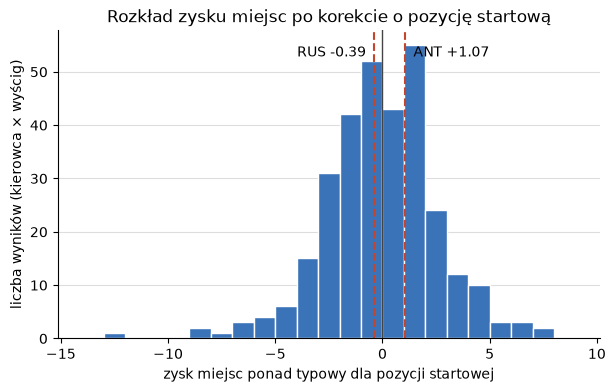

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = range(-14, 10)
ax.hist(finishers["gain_vs_expected"], bins=bins, color="#3b73b9", edgecolor="white", linewidth=1)
ax.axvline(0, color="#444444", linewidth=1)
for name, ha in [("ANT", "left"), ("RUS", "right")]:
    value = skill.loc[name, "gain_vs_expected"]
    ax.axvline(value, color="#c4452d", linewidth=1.5, linestyle="--")
    ax.text(value, ax.get_ylim()[1] * 0.95, f"{name} {value:+.2f}  " if ha == "right" else f"  {name} {value:+.2f}", ha=ha, va="top")
ax.set_xlabel("zysk miejsc ponad typowy dla pozycji startowej")
ax.set_ylabel("liczba wyników (kierowca × wyścig)")
ax.set_title("Rozkład zysku miejsc po korekcie o pozycję startową")
ax.grid(axis="y", color="#dddddd", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.show()

### Wykres per kierowca do 2.4

**Co robimy:** zamiast jednego histogramu — jeden „pudełkowy” wykres na kierowcę, żeby widać było rozrzut jego wyników, a nie tylko średnią.

/var/folders/z5/qs2sdjb56wj01zq7ls4v9cn80000gn/T/ipykernel_10379/3241705175.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(groups, vert=False, tick_labels=order, widths=0.6, patch_artist=True,


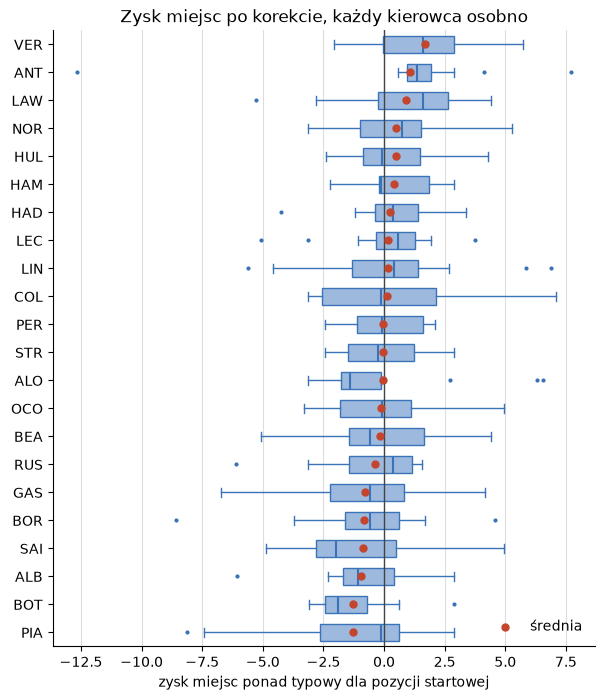

In [14]:
order = skill[skill["races"] >= 5].sort_values("gain_vs_expected").index
groups = [finishers.loc[finishers["name_acronym"] == name, "gain_vs_expected"].dropna() for name in order]

fig, ax = plt.subplots(figsize=(7, 8))
ax.boxplot(groups, vert=False, tick_labels=order, widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#9db9de", edgecolor="#3b73b9"),
           medianprops=dict(color="#3b73b9", linewidth=1.5),
           whiskerprops=dict(color="#3b73b9"), capprops=dict(color="#3b73b9"),
           flierprops=dict(marker="o", markersize=3, markerfacecolor="#3b73b9", markeredgecolor="none"))
ax.scatter([g.mean() for g in groups], range(1, len(groups) + 1), color="#c4452d", zorder=3, s=25, label="średnia")
ax.axvline(0, color="#444444", linewidth=1)
ax.set_xlabel("zysk miejsc ponad typowy dla pozycji startowej")
ax.set_title("Zysk miejsc po korekcie, każdy kierowca osobno")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="x", color="#dddddd", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.show()

## 2.5 Braki w danych

**Co robimy:** sprawdzamy, w których kolumnach są puste wartości (`NaN`) i skąd się biorą.

**Dlaczego:** puste wartości po cichu psują średnie, korelacje i modele. Już raz zjadły nam pudełka na wykresie. Zanim zbudujemy cokolwiek dalej, chcemy wiedzieć, czy braki są **uzasadnione** (np. kierowca, który nie ukończył wyścigu, nie ma pozycji na mecie), czy to **dziura w danych**, którą trzeba załatać.

In [15]:
all_rows = results[["round", "name_acronym", "position", "dnf", "dns"]].merge(
    quali[["round", "name_acronym", "position"]],
    on=["round", "name_acronym"], how="left", suffixes=("_race", "_quali"),
)

print("Braki w kolumnach:")
print(all_rows[["position_race", "position_quali"]].isna().sum())
print()
print("Brak pozycji na mecie, a wyścig ukończony:", (all_rows["position_race"].isna() & ~all_rows["dnf"] & ~all_rows["dns"]).sum())
print("Brak pozycji w kwalifikacjach:", all_rows["position_quali"].isna().sum())
all_rows[all_rows["position_quali"].isna()]

Braki w kolumnach:
position_race     74
position_quali     7
dtype: int64

Brak pozycji na mecie, a wyścig ukończony: 2
Brak pozycji w kwalifikacjach: 7


,round,name_acronym,position_race,dnf,dns,position_quali
5,1,VER,6.0,False,False,NaN
14,1,SAI,15.0,False,False,NaN
16,1,STR,NaN,False,False,NaN
87,4,HAD,NaN,True,False,NaN
301,14,BEA,16.0,False,False,NaN
306,14,STR,NaN,True,False,NaN
361,17,HAD,10.0,False,False,NaN


## 2.6 Jak mocno pozycja w kwalifikacjach przewiduje wynik?

**Co robimy:** liczymy korelację między pozycją startową (kwalifikacje) a pozycją na mecie — raz dla wszystkich wyścigów razem, raz osobno dla każdego wyścigu.

**Dlaczego:** to mówi, ile informacji niesie sama pozycja startowa. Jeśli korelacja jest bliska 1, to start z przodu prawie przesądza o wyniku i model ma niewiele do dodania. Wyścigi, w których korelacja jest niska, to te „nieprzewidywalne” (deszcz, kary, chaos).

Używamy korelacji **Spearmana**: porównuje kolejność, a nie wartości, więc pasuje do pozycji (1., 2., 3...).

In [16]:
both = all_rows.dropna(subset=["position_race", "position_quali"])

overall = both["position_quali"].corr(both["position_race"], method="spearman")
per_race = both.groupby("round").apply(lambda g: g["position_quali"].corr(g["position_race"], method="spearman"), include_groups=False)

print(f"Korelacja Spearmana (wszystkie wyścigi razem): {overall:.2f}   (n = {len(both)})")
print(f"Po wyścigach: min {per_race.min():.2f}, średnia {per_race.mean():.2f}, max {per_race.max():.2f}")
per_race.round(2).sort_values()

Korelacja Spearmana (wszystkie wyścigi razem): 0.83   (n = 318)
Po wyścigach: min 0.61, średnia 0.83, max 0.98


round
9     0.61
7     0.64
6     0.65
16    0.67
15    0.67
5     0.79
12    0.85
13    0.87
2     0.88
4     0.88
1     0.89
8     0.92
3     0.92
11    0.92
17    0.94
10    0.96
18    0.96
14    0.98
dtype: float64

## 2.7 Czy awarie mieszają kolejność?

**Co robimy:** dla każdego wyścigu zestawiamy liczbę kierowców, którzy go nie ukończyli (DNF), z korelacją start→meta z 2.6.

**Dlaczego:** sprawdzamy hipotezę, że chaotyczne wyścigi (dużo awarii i wypadków) mają niską korelację. Jeśli tak jest, to częściowo wyjaśnia, dlaczego niektóre wyścigi są nieprzewidywalne. Jeśli nie, przyczyna leży gdzie indziej (np. w różnicach tempa samochodów).

In [17]:
per_round = races[races["round"].isin(results["round"].unique())][["round", "location"]].set_index("round")
per_round["dnf_count"] = all_rows.groupby("round")["dnf"].sum()
per_round["spearman"] = per_race.round(2)

print("Korelacja liczby DNF z korelacją start→meta:", round(per_round["dnf_count"].corr(per_round["spearman"], method="spearman"), 2))
per_round.sort_values("spearman")

Korelacja liczby DNF z korelacją start→meta: -0.4


,location,dnf_count,spearman
round,,,
9,Silverstone,3,0.61
7,Barcelona,7,0.64
6,Monte Carlo,7,0.65
16,Kuala Lumpur,3,0.67
15,Baku,7,0.67
5,Montréal,5,0.79
12,Zandvoort,6,0.85
13,Monza,3,0.87
2,Shanghai,3,0.88


## 2.8 Historia Meksyku (2023–2025)

**Co robimy:** sprawdzamy, jak wyglądały trzy poprzednie GP Meksyku: czy wygrywało pole position, jak mocno start przewidywał metę i kto stał na podium.

**Dlaczego:** tor jest ten sam, więc może mieć swoje cechy (wysokość, długa prosta startowa, słaby docisk), które odróżniają go od reszty sezonu. Próbka to **tylko 3 wyścigi**, więc to wskazówka, a nie dowód. Samochody z lat 2023–2025 były inne niż w 2026 (inne przepisy), więc patrzymy na cechy toru, a nie na to, kto jest szybki.

In [18]:
poles = mexico_hist[mexico_hist["quali_pos"] == 1]
print("Pole position wygrywało wyścig w Meksyku:", (poles["race_pos"] == 1).sum(), "z", len(poles))
print()
print("Korelacja start→meta w Meksyku, rok po roku:")
print(mexico_hist.groupby("year").apply(lambda g: g["quali_pos"].corr(g["race_pos"], method="spearman"), include_groups=False).round(2))
print()
mexico_hist[mexico_hist["race_pos"] <= 3].sort_values(["year", "race_pos"])[["year", "race_pos", "quali_pos", "name_acronym", "team_name"]]

Pole position wygrywało wyścig w Meksyku: 2 z 3

Korelacja start→meta w Meksyku, rok po roku:
year
2023    0.61
2024    0.85
2025    0.72
dtype: float64



,year,race_pos,quali_pos,name_acronym,team_name
0,2023,1.0,3.0,VER,Red Bull Racing
1,2023,2.0,6.0,HAM,Mercedes
2,2023,3.0,1.0,LEC,Ferrari
20,2024,1.0,1.0,SAI,Ferrari
21,2024,2.0,3.0,NOR,McLaren
22,2024,3.0,4.0,LEC,Ferrari
40,2025,1.0,1.0,NOR,McLaren
41,2025,2.0,2.0,LEC,Ferrari
42,2025,3.0,5.0,VER,Red Bull Racing


## 2.9 Wnioski z EDA

**Co ustaliliśmy (dane: 18 zakończonych wyścigów 2026, ok. 400 wierszy):**
- **Punkt odniesienia:** reguła „wygra pole position” trafia w 13 z 18 wyścigów (72%). Model musi być od niej lepszy.
- **Pozycja startowa** mocno wyjaśnia metę (Spearman 0,83), ale w różnych wyścigach od 0,61 do 0,98.
- **Awarie** częściowo mieszają kolejność (korelacja −0,40 z korelacją start→meta), ale nie tłumaczą wszystkiego.
- **Zysk miejsc trzeba korygować o pozycję startową**: z końca stawki łatwo zyskać, z czoła łatwo stracić. Po korekcie wyróżniają się m.in. ANT (+1,07) i VER (+1,69), a RUS (−0,39) i PIA (−1,29) są na minusie. Przy 6–17 wyścigach na kierowcę to słaby sygnał.
- **Meksyk (2023–2025):** pole wygrywało 2 z 3, start przewidywał metę nieco słabiej niż w typowym wyścigu (0,61–0,85), LEC był na podium trzy razy. To tylko 3 wyścigi z innymi samochodami.
- **Historia partnerów z lat 2023–2025** dotyczy 22 z 23 kierowców, ale debiutanci (ANT, BOR, HAD, LIN) mają jej mało lub wcale, a średnia psują skrajne wartości (trzeba mediany).

**Kandydaci na zmienne do modelu:**
1. pozycja w kwalifikacjach i strata do pole (%),
2. zysk miejsc kierowcy po korekcie (liczony tylko z wyścigów *przed* przewidywanym),
3. awaryjność zespołu i kierowcy (z ostrożnością przy małych próbach),
4. forma zespołu z ostatnich wyścigów (okno do sprawdzenia: 2, 3 lub 5),
5. mediana różnicy do partnera z lat 2023–2025 (ostrożnie, zwłaszcza dla debiutantów).

**Zasada:** zmienna zostaje w modelu tylko wtedy, gdy poprawia wynik na wyścigach, których model nie widział (walk-forward w `03_model`). Cechy liczymy wyłącznie z danych sprzed przewidywanego wyścigu, żeby nie dopuścić do wycieku danych.